# M2 · 04 — Statistical Analysis

These are tests on the **cleaned** data (`data/processed/`, all splits combined unless stated). Each test states its hypothesis, statistic, p-value, effect size and what it means for modelling. Significance level α = 0.05.

In [1]:
# Requires the project package: `pip install -e ".[analysis]"` from the repository root.
import collections
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from medibridge.config import ENTITY_TYPES, SUBSETS
from medibridge.io import load_all_splits
from medibridge.split import cramers_v
from medibridge.text import tokenize

In [2]:
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)


data = {s: load_all_splits(s) for s in SUBSETS}
both = pd.concat(data.values(), ignore_index=True)
both["entity_density"] = both["n_entities"] / both["n_tokens"].clip(lower=1)
spans = pd.DataFrame(
    [
        {"subset": r.subset, "context": r.context, "split": r.split, **e}
        for r in both.itertuples()
        for e in r.entities
    ]
)

## 1. Descriptive statistics

In [3]:
desc = both.groupby(["subset", "context"])[
    ["duration", "n_tokens", "n_entities", "entity_density", "cmi"]
].agg(["mean", "median", lambda s: s.quantile(0.75) - s.quantile(0.25), "skew"])
desc.columns = [f"{a}_{'IQR' if b == '<lambda_0>' else b}" for a, b in desc.columns]
desc.round(2).T

subset                          en                                               hi                   
context               conversation narration_entity narration_sentence conversation narration_sentence
duration_mean                14.47             4.02              15.27        15.57              19.13
duration_median              13.00             3.72              15.12        13.41              19.05
duration_IQR                  9.24             1.56               4.13         9.70               4.91
duration_skew                 0.07             3.42               0.01         0.25              -0.46
n_tokens_mean                35.24             3.59              38.30        57.11              36.15
n_tokens_median              31.00             3.00              39.00        50.50              36.00
n_tokens_IQR                 26.00             2.00               8.00        33.75               9.00
n_tokens_skew                 1.05             2.47              -0.06         0.59               0.17
n_entities_mean               4.72             1.00               6.21         4.70               6.01
n_entities_median             4.00             1.00               6.00         4.50               6.00
n_entities_IQR                3.00             0.00               3.00         3.75               2.00
n_entities_skew               0.96             0.00               0.64         0.56               0.39
entity_density_mean           0.15             0.42               0.16         0.08               0.17
entity_density_median         0.14             0.33               0.16         0.08               0.17
entity_density_IQR            0.10             0.25               0.07         0.06               0.06
entity_density_skew           0.58             1.19               0.45         0.76               0.46
cmi_mean                      0.00             0.00               0.00         6.22               0.20
cmi_median                    0.00             0.00               0.00         0.00               0.00
cmi_IQR                       0.00             0.00               0.00         0.00               0.00
cmi_skew                      0.00             0.00               0.00         1.93               5.28

Durations and token counts are **right-skewed** (skew > 0), so the tests below use rank-based, non-parametric methods (Mann–Whitney U, Spearman) rather than t-tests or Pearson.

## 2. Does the entity-type mix depend on the recording context? (χ² test of independence)
**H0:** entity type is independent of recording context (conversation vs narration) in `hi`.

In [4]:
hi_spans = spans[spans.subset == "hi"]
t1 = pd.crosstab(hi_spans["context"], hi_spans["type"])[list(ENTITY_TYPES)]
chi2, p, dof, _ = stats.chi2_contingency(t1)
display(t1)
print(f"chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v(t1):.2f}")

type,drugs,clinical_findings,diagnostics,advices,misc_medical
context,,,,,
conversation,113,247,102,84,46
narration_sentence,728,377,4,16,16


chi2 = 504.9, dof = 4, p = 5.75e-108, Cramér's V = 0.54


**Result:** we reject H0 (p ≈ 10⁻¹⁰⁸) with a **strong** association (V ≈ 0.54). Narrations are mostly *drugs*, while conversations carry nearly all *diagnostics* and *advices*. **Implication:** we stratify the split by context (done in `05_…`) and will report metrics per context in M4.

## 3. Is the entity-type mix different between Hindi and English data? (χ²)
**H0:** the entity-type distribution is the same in `hi` and `en`.

In [5]:
t2 = pd.crosstab(spans["subset"], spans["type"])[list(ENTITY_TYPES)]
chi2, p, dof, _ = stats.chi2_contingency(t2)
display((t2.T / t2.sum(axis=1)).T.mul(100).round(1))
print(f"chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v(t2):.2f}")

type,drugs,clinical_findings,diagnostics,advices,misc_medical
subset,,,,,
en,23.3,52.4,9.7,3.4,11.1
hi,48.5,36.0,6.1,5.8,3.6


chi2 = 557.7, dof = 4, p = 2.16e-119, Cramér's V = 0.22


**Result:** we reject H0 with a **moderate** effect (V ≈ 0.22). `en` has twice the share of clinical findings and `hi` twice the share of drugs. **Implication:** `en` helps as auxiliary training data but is not a stand-in for `hi`, so we evaluate on `hi` test.

## 4. Are conversations different from narrations? (Mann–Whitney U, `hi`)
**H0:** conversations and narrated sentences have the same distribution of (a) length, (b) entity density, (c) code-mixing.

In [6]:
hi = data["hi"].assign(entity_density=lambda d: d.n_entities / d.n_tokens.clip(lower=1))
rows = []
for col in ("n_tokens", "entity_density", "cmi"):
    a = hi.loc[hi.context == "conversation", col]
    b = hi.loc[hi.context == "narration_sentence", col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rbc = 1 - 2 * u / (len(a) * len(b))  # rank-biserial correlation (effect size)
    rows.append(
        {
            "variable": col,
            "median conversation": round(a.median(), 3),
            "median narration": round(b.median(), 3),
            "U": round(u, 1),
            "p": f"{p:.2e}",
            "effect size (rank-biserial)": round(rbc, 2),
        }
    )
pd.DataFrame(rows)

,variable,median conversation,median narration,U,p,effect size (rank-biserial)
0,n_tokens,50.500,36.000,18734.0,1.73e-17,-0.57
1,entity_density,0.083,0.167,2536.5,1.84e-32,0.79
2,cmi,0.000,0.000,13932.0,7.78e-06,-0.16


**Result:** all three differences are significant. Conversations are **longer** (large effect), have **half the entity density** (0.08 vs 0.17 entities per token; large effect) and are **more code-mixed** (small effect). **Implication:** a model tuned on narrations will meet many more non-entity tokens in real conversations, so precision on conversations is the metric to watch.

## 5. Correlations (Spearman ρ)

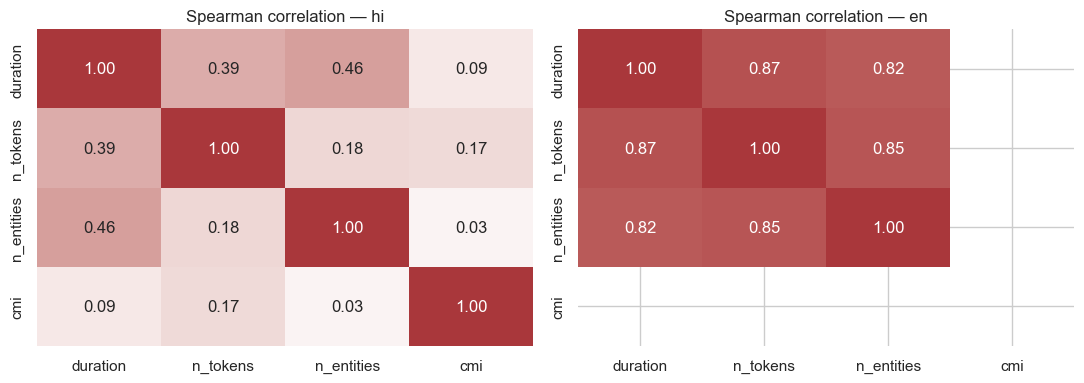

hi: duration vs number of entities: rho = 0.46, p = 3.65e-18


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s in zip(axes, ("hi", "en")):
    corr = data[s][["duration", "n_tokens", "n_entities", "cmi"]].corr(method="spearman")
    sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax, cbar=False)
    ax.set_title(f"Spearman correlation — {s}")
plt.tight_layout()
plt.savefig(FIG / "06_correlations.png", dpi=150)
plt.show()
rho, p = stats.spearmanr(data["hi"]["duration"], data["hi"]["n_entities"])
print(f"hi: duration vs number of entities: rho = {rho:.2f}, p = {p:.2e}")

**Result:** longer recordings carry more entities (moderate ρ ≈ 0.46 in `hi`). Duration and token count are strongly correlated, as expected, so the transcripts are consistent with the audio.

## 6. Lexical statistics and Zipf's law

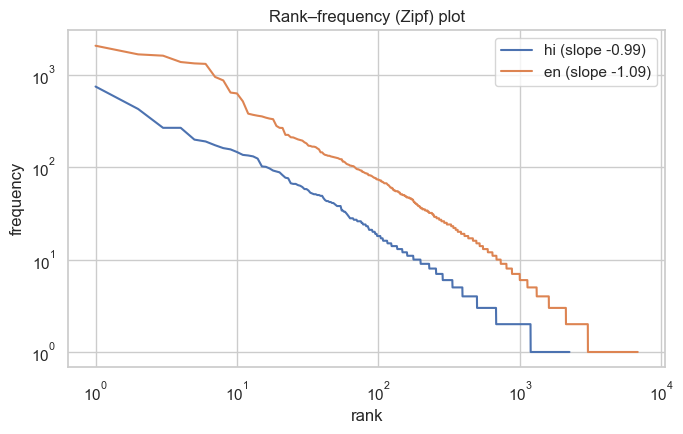

,hi,en
tokens,12300.000,52647.000
vocabulary,2242.000,6810.000
type-token ratio,0.182,0.129
hapax ratio (words seen once),0.470,0.556
Zipf slope,-0.990,-1.090


In [8]:
def tokens_of(df):
    return [t.lower() for txt in df["text"] for t, _, _ in tokenize(txt) if re.search(r"\w", t)]


lex = {}
fig, ax = plt.subplots(figsize=(7, 4.5))
for s in SUBSETS:
    toks = tokens_of(data[s])
    freq = collections.Counter(toks)
    lex[s] = {
        "tokens": len(toks),
        "vocabulary": len(freq),
        "type-token ratio": round(len(freq) / len(toks), 3),
        "hapax ratio (words seen once)": round(sum(v == 1 for v in freq.values()) / len(freq), 3),
    }
    ranks = np.arange(1, len(freq) + 1)
    counts = np.array(sorted(freq.values(), reverse=True))
    slope = np.polyfit(np.log(ranks), np.log(counts), 1)[0]
    lex[s]["Zipf slope"] = round(slope, 2)
    ax.loglog(ranks, counts, label=f"{s} (slope {slope:.2f})")
ax.set(title="Rank–frequency (Zipf) plot", xlabel="rank", ylabel="frequency")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "07_zipf.png", dpi=150)
plt.show()
pd.DataFrame(lex)

**Result:** both subsets follow Zipf's law (slope ≈ −1), the usual signature of natural language, and have a long tail: about half the vocabulary appears only once. **Implication:** rare drug and brand names dominate the vocabulary, so subword or character-aware models are needed.

## 7. Generalisation difficulty: out-of-vocabulary rates across splits
How much of the validation and test data was never seen in training? A high entity OOV rate means a model cannot simply memorise drug names and has to generalise.

In [9]:
oov = {}
for s in SUBSETS:
    d = data[s]
    train_vocab = set(tokens_of(d[d.split == "train"]))
    train_ents = {e["text"].lower() for es in d.loc[d.split == "train", "entities"] for e in es}
    for sp in ("val", "test"):
        part = d[d.split == sp]
        toks = tokens_of(part)
        ents = [e["text"].lower() for es in part["entities"] for e in es]
        oov[(s, sp)] = {
            "token OOV %": round(100 * np.mean([t not in train_vocab for t in toks]), 1),
            "entity-surface OOV %": round(100 * np.mean([e not in train_ents for e in ents]), 1),
        }
pd.DataFrame(oov).T

token OOV %  entity-surface OOV %
hi val          17.5                  67.6
   test         24.0                  72.3
en val           9.0                  57.6
   test          9.1                  54.7

**Result:** **68–72% of entity mentions in `hi` validation and test never occur in `hi` train.** A dictionary or memorisation approach would fail. **Implication:** this supports the M1 design of translation, zero-shot English NER (GLiNER) and projection, which generalises to unseen drug names.

## 8. Class imbalance

In [10]:
imb = pd.crosstab(spans["type"], spans["subset"])[["hi", "en"]].reindex(ENTITY_TYPES)
imb.loc["imbalance ratio (max / min)"] = (imb.max() / imb.min()).round(1)
imb

subset,hi,en
type,,
drugs,841.0,2401.0
clinical_findings,624.0,5407.0
diagnostics,106.0,1003.0
advices,100.0,353.0
misc_medical,62.0,1145.0
imbalance ratio (max / min),13.6,15.3


**Result:** the largest class is about 14× the smallest (`misc_medical`, `advices`). **Implication:** we report **macro-F1** alongside micro-F1 and consider class weights, so that rare but clinically important types are not hidden.

## 9. Confidence interval for code-mixing in conversations (bootstrap)

In [11]:
conv = data["hi"].query("context == 'conversation'")["cmi"].to_numpy()
rng = np.random.default_rng(42)
boots = [rng.choice(conv, len(conv), replace=True).mean() for _ in range(5000)]
lo, hi_ = np.percentile(boots, [2.5, 97.5])
print(
    f"mean CMI in hi conversations = {conv.mean():.2f}  (95% bootstrap CI {lo:.2f} – {hi_:.2f}), n = {len(conv)}"
)
print(f"share of conversation transcripts with any code-mixing (CMI > 0): {(conv > 0).mean():.1%}")

mean CMI in hi conversations = 6.22  (95% bootstrap CI 3.99 – 8.64), n = 126
share of conversation transcripts with any code-mixing (CMI > 0): 20.6%


**Result:** script-based CMI is low on average but clearly non-zero in conversations, with a bootstrap 95% CI excluding 0. Because English words in Devanagari count as Hindi, this is a **lower bound** on the real mixing (see EDA §5).

## Summary of statistical findings
| Question | Test | Result | What we do about it |
|---|---|---|---|
| Entity type vs context (`hi`) | χ², Cramér's V | Strong dependence (V ≈ 0.54) | Stratified split; per-context metrics |
| `hi` vs `en` label mix | χ² | Moderate difference (V ≈ 0.22) | `en` is auxiliary; evaluate on `hi` |
| Conversation vs narration | Mann–Whitney U | Longer, half the entity density | Watch precision on conversations |
| Unseen entities in val/test | OOV rate | 68–72% unseen in `hi` | Zero-shot / translation pipeline, not a dictionary |
| Class balance | max/min ratio | about 14:1 | Macro-F1, class weights |